# 🌸 الأعمال التطبيقية 3 (TP3): التصنيف الخاضع للإشراف — بيانات أزهار السوسن (Fisher's Iris)
### عمل مخبري أكاديمي | الفصل الرابع: التصنيف (Chapter IV: Classification)
**المادة:** التعلّم الآلي والتعرّف الإحصائي على الأنماط (Machine Learning & Statistical Pattern Recognition)  
**بيئة العمل:** متوافق بالكامل مع Google Colab و VS Code  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saoula2026/ml_univ/blob/main/TP3/iris_dataset/TP3_Iris_Arabic.ipynb)

---

## 🎯 أهداف العمل التطبيقي ومحتوى المقرر
في هذا العمل التطبيقي (**TP3**)، نُجري دراسة تجريبية ونظرية شاملة ودقيقة لـ **11 خوارزمية تصنيف أساسية** تمت تغطيتها في **الفصل الرابع: التصنيف (Chapter IV: Classification)** مطبقة على مسألة **تصنيف متعدد الفئات (Multi-Class Classification, $C=3$)**:

1. **الانحدار اللوجستي متعدد الحدود (Multinomial Logistic Regression)** (دالة Softmax والإنتروبيا المتقاطعة الفئوية)
2. **الانحدار اللوجستي متعدد الحدود (Polynomial Logistic Regression)** (التوسع في فضاء الخصائص التفاعلية)
3. **البيرسبترون البسيط (Simple Perceptron)** (وحدة العتبة الخطية مع استراتيجية One-vs-Rest)
4. **البيرسبترون متعدد الطبقات (Multi-Layer Perceptron - MLP)** (الشبكات العصبية مع مخرجات Softmax)
5. **شجرة القرار باستخدام كسب المعلومات (Decision Tree - Entropy)** (إنتروبيا شانون للتصنيف المتعدد)
6. **شجرة القرار باستخدام شوائب جيني (Decision Tree - Gini Impurity)** (مقياس جيني متعدد الفئات)
7. **الغابة العشوائية (Random Forest Classifier)** (تجميع الأشجار العشوائية مع التصويت بالأغلبية)
8. **خوارزمية الجيران الأقرب ($k$-NN - K-Nearest Neighbors)** (التصويت القائم على المسافة الإقليدية)
9. **نايف بايز الغاوسي (Gaussian Naive Bayes)** (الاحتمالية الغاوسية مع فرضية الاستقلالية الشرطية)
10. **آلة المتجهات الداعمة الخطية (Linear SVM)** (مستويات الهامش الأقصى وفق بنية One-vs-Rest)
11. **آلة المتجهات الداعمة غير الخطية (Non-Linear SVM - RBF Kernel)** (الإسقاط في فضاء هيلبرت عبر نواة RBF)

### المخطط المنهجي المتبع:
* **القسم 1: استكشاف وتحليل البيانات (EDA):** الخصائص المورفولوجية، وتوزيع الفئات، وخريطة الارتباط، ومخططات التشتت التفاعلية.
* **القسم 2: معالجة البيانات واستراتيجية التحقق:** معالجة الارتباط، والتقسيم الطبقي للبيانات (Stratified Hold-out)، والمعايرة القياسية بدون تسريب للبيانات.
* **القسم 3: التدريب والصياغة الرياضية والتقييم الشامل لكل نموذج:** المعادلات النظرية، والتحقق المتقاطع الخماسي الطبقي، ومصفوفة الالتباس 3x3 ومنحنيات ROC بتفكيك One-vs-Rest.
* **القسم 4: ضبط المعاملات الفائقة (Hyperparameter Optimization):** استخدام البحث الشبكي (`GridSearchCV`) لتحسين الغابة العشوائية و SVM.
* **القسم 5: المقارنة النهائية والاستنتاج الأكاديمي:** جدول مقارنة تركيبي شامل، ورسوم بيانية مقارنة، واستنتاج أكاديمي تحليلي شامل.

In [1]:
# ==============================================================================
# القسم 0: إعداد بيئة العمل واستيراد المكتبات البرمجية
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

# مكتبات الحساب العلمي ومعالجة البيانات
import numpy as np
import pandas as pd

# مكتبات الرسم البياني والتمثيل المرئي
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# ضبط عارض Plotly ليتوافق مع VS Code و Google Colab
pio.renderers.default = "notebook_connected"

# Scikit-Learn: البيانات والتحقق المتقاطع
from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

# Scikit-Learn: نماذج التصنيف الـ 11
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Scikit-Learn: مقاييس تقييم الأداء
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report
)

# الإعدادات العامة لجماليات الرسوم البيانية
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14

# تثبيت البذرة العشوائية لضمان إمكانية إعادة إنتاج النتائج
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✅ تم استيراد جميع المكتبات المطلوبة بنجاح.")
print(f"📊 إصدار NumPy: {np.__version__}")
print(f"🐼 إصدار Pandas: {pd.__version__}")

✅ تم استيراد جميع المكتبات المطلوبة بنجاح.
📊 إصدار NumPy: 2.4.6
🐼 إصدار Pandas: 3.0.3


## 1. تحميل واستكشاف البيانات (Data Loading & EDA)

تُعتبر مجموعة **أزهار السوسن (Iris Flower Dataset)** التي قدمها عالم الإحصاء والأحياء البريطاني رونالد فيشر (Ronald A. Fisher, 1936) أشهر مجموعة بيانات كلاسيكية في تاريخ التعلّم الآلي.

تتألف البيانات من:
* **عدد العينات:** 150 عينة بيولوجية (50 عينة لكل فئة).
* **الخصائص:** 4 قياسات مورفولوجية مقاسة بالسنتيمتر (cm):
  1. `sepal length (cm)` — طول السبلة
  2. `sepal width (cm)` — عرض السبلة
  3. `petal length (cm)` — طول البتلة
  4. `petal width (cm)` — عرض البتلة
* **الفئات المستهدفة:** 3 أصناف متميزة من أزهار السوسن:
  * `0`: **سوسن سيتوسا (Iris-setosa)** (منفصلة خطياً تماماً عن الصنفين الآخرين)
  * `1`: **سوسن فرسيكولور (Iris-versicolor)** (تتداخل حدودها مع فيرجينيكا)
  * `2`: **سوسن فيرجينيكا (Iris-virginica)** (متداخلة جزئياً في أبعاد السبلات)

In [2]:
# تحميل بيانات أزهار السوسن من Scikit-Learn
raw_iris = load_iris(as_frame=True)
df = raw_iris.frame.copy()

# إضافة عمود التسمية النصية باللغة العربية والإنجليزية
species_map = {0: 'Setosa (سيتوسا)', 1: 'Versicolor (فرسيكولور)', 2: 'Virginica (فيرجينيكا)'}
df['species'] = df['target'].map(species_map)

# عرض أبعاد وهيكل البيانات
print(f"أبعاد البيانات: {df.shape[0]} عينة، {df.shape[1]} أعمدة (4 خصائص + الفئة الرقمية + التسمية التصنيفية)")
df.head(10)

أبعاد البيانات: 150 عينة، 6 أعمدة (4 خصائص + الفئة الرقمية + التسمية التصنيفية)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,Setosa (سيتوسا)
1,4.9,3.0,1.4,0.2,0,Setosa (سيتوسا)
2,4.7,3.2,1.3,0.2,0,Setosa (سيتوسا)
3,4.6,3.1,1.5,0.2,0,Setosa (سيتوسا)
4,5.0,3.6,1.4,0.2,0,Setosa (سيتوسا)
5,5.4,3.9,1.7,0.4,0,Setosa (سيتوسا)
6,4.6,3.4,1.4,0.3,0,Setosa (سيتوسا)
7,5.0,3.4,1.5,0.2,0,Setosa (سيتوسا)
8,4.4,2.9,1.4,0.2,0,Setosa (سيتوسا)
9,4.9,3.1,1.5,0.1,0,Setosa (سيتوسا)


In [3]:
# معلومات موجزة حول أنواع البيانات والقيم المفقودة
print("--- معلومات إطار البيانات (Dataframe Info) ---")
df.info()

print("\n--- فحص القيم المفقودة (Missing Values) ---")
missing_counts = df.isnull().sum()
print(f"إجمالي القيم المفقودة في كافة الخلايا: {missing_counts.sum()}")

print("\n--- فحص الصفوف المكررة (Duplicate Rows) ---")
duplicate_count = df.duplicated().sum()
print(f"إجمالي الصفوف المكررة: {duplicate_count}")

--- معلومات إطار البيانات (Dataframe Info) ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 11.2 KB

--- فحص القيم المفقودة (Missing Values) ---
إجمالي القيم المفقودة في كافة الخلايا: 0

--- فحص الصفوف المكررة (Duplicate Rows) ---
إجمالي الصفوف المكررة: 1


In [4]:
# الإحصاءات الوصفية للخصائص المورفولوجية
df.drop(columns=['target', 'species']).describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,mean,std,min,25%,50%,75%,max
sepal length (cm),5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


--- توزيع فئات أصناف السوسن ---


,العدد (Count),النسبة المئوية (%)
species,,
Setosa (سيتوسا),50,33.33
Versicolor (فرسيكولور),50,33.33
Virginica (فيرجينيكا),50,33.33


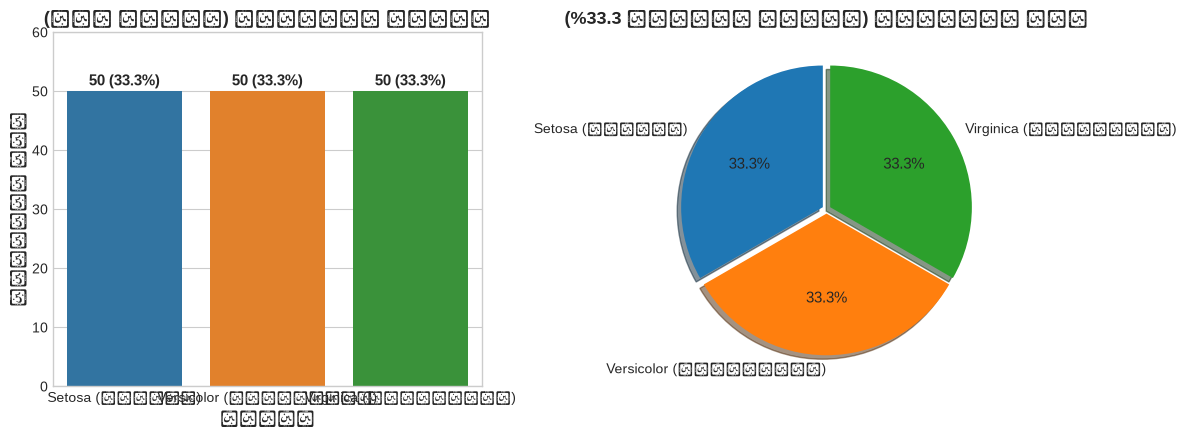

In [5]:
# تحليل توازن الفئات المستهدفة (Class Distribution)
class_counts = df['species'].value_counts()
class_percentages = df['species'].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    'العدد (Count)': class_counts,
    'النسبة المئوية (%)': class_percentages.round(2)
})
print("--- توزيع فئات أصناف السوسن ---")
display(class_summary)

# رسم بياني لتوزيع الفئات
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# مخطط الأعمدة
sns.barplot(x=class_summary.index, y=class_summary['العدد (Count)'], palette=['#1f77b4', '#ff7f0e', '#2ca02c'], ax=axes[0])
axes[0].set_title("تكرار الأصناف (توازن تام)", fontweight='bold')
axes[0].set_ylabel("عدد العينات")
axes[0].set_xlabel("الصنف")
for i, count in enumerate(class_summary['العدد (Count)']):
    axes[0].text(i, count + 1, f"{count} ({class_percentages.iloc[i]:.1f}%)", ha='center', fontweight='bold')
axes[0].set_ylim(0, 60)

# المخطط الدائري
axes[1].pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    colors=['#1f77b4', '#ff7f0e', '#2ca02c'],
    startangle=90,
    explode=[0.03, 0.03, 0.03],
    shadow=True
)
axes[1].set_title("نسب الأصناف (توزيع متكافئ 33.3%)", fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
# مخطط تشتت تفاعلي (Plotly Express)
fig_eda = px.scatter(
    df,
    x='petal length (cm)',
    y='petal width (cm)',
    color='species',
    symbol='species',
    color_discrete_map={'Setosa (سيتوسا)': '#1f77b4', 'Versicolor (فرسيكولور)': '#ff7f0e', 'Virginica (فيرجينيكا)': '#2ca02c'},
    hover_data=['sepal length (cm)', 'sepal width (cm)'],
    title="تحليل استكشافي تفاعلي: طول البتلة مقابل عرض البتلة عبر أصناف السوسن",
    labels={'petal length (cm)': 'طول البتلة (Petal Length)', 'petal width (cm)': 'عرض البتلة (Petal Width)'},
    template='plotly_white',
    marginal_x='violin',
    marginal_y='box'
)
fig_eda.update_layout(width=900, height=550)
fig_eda.show()

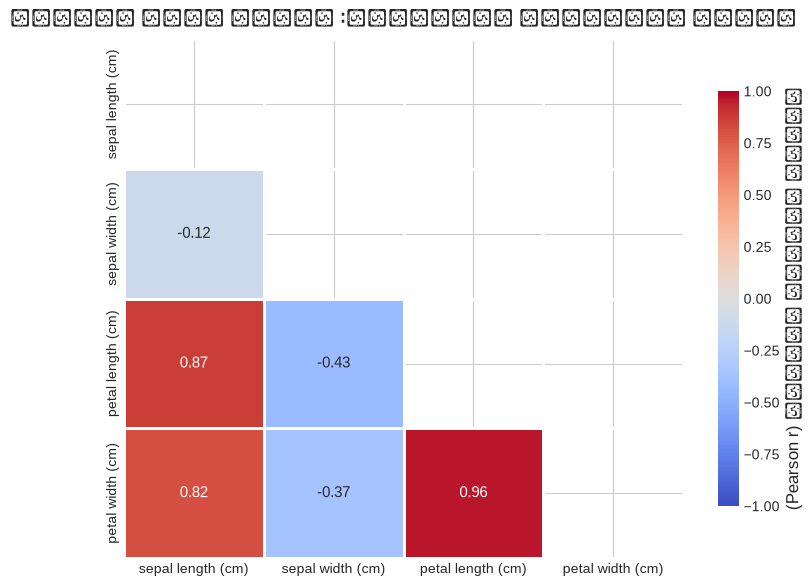

In [7]:
# خريطة الارتباط الحرارية للخصائص المورفولوجية
features_only = df.drop(columns=['target', 'species'])
corr_matrix = features_only.corr()

plt.figure(figsize=(7.5, 6))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=1.0,
    cbar_kws={"shrink": 0.8, "label": "معامل ارتباط بيرسون (Pearson r)"}
)
plt.title("خريطة الارتباط الحرارية: خصائص زهرة السوسن", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

> [!NOTE]
> ### 🔍 أهم الملاحظات المستخلصة من التحليل الاستكشافي:
> 1. **الارتباط الخطي القوي بين أبعاد البتلات:**
>    * ارتباط مرتفع جداً بين `petal length (cm)` و `petal width (cm)` بقيمة ($r = 0.96$).
>    * ارتباط قوي بين `sepal length (cm)` و `petal length (cm)` بقيمة ($r = 0.87$).
>    * ارتباط سلبي متوسط بين `sepal width (cm)` و `petal length (cm)` بقيمة ($r = -0.43$).
> 2. **الهندسة الفضائية للعناقيد:**
>    * تشكل فئة *Setosa* عنقوداً معزولاً ومنفصلاً خطياً تماماً ببتلات صغيرة ($L < 2.0\text{ cm}, W < 0.8\text{ cm}$).
>    * تتجاور فئتا *Versicolor* و *Virginica* وتتداخلان جزئياً عند حدود طول البتلة $\approx 4.8 - 5.1\text{ cm}$، مما يتطلب حدود فصل غير خطية أو هوامش مرنة للفصل الدقيق.

## 2. معالجة البيانات واستراتيجية التحقق (Data Preprocessing)

### 2.1 الارتباط الخطي واستبقاء الخصائص
تُظهر أبعاد البتلة ارتباطاً شديداً ($r=0.96$). مع ذلك، نحتفظ بجميع الخصائص الـ 4 لمقارنة سلوك الخوارزميات الـ 11 عبر المعيار القياسي نفسه.

### 2.2 ترميز الفئات (Target Encoding)
* `0`: **Setosa (سيتوسا)**
* `1`: **Versicolor (فرسيكولور)**
* `2`: **Virginica (فيرجينيكا)**

### 2.3 استراتيجية التقسيم الطبقي للبيانات (الفصل الرابع، القسم 9)
وفقاً لـ **القسم 9 من الفصل الرابع**، يتطلب التقييم الصارم تجزئة متوازنة:
$$\mathcal{D} = \mathcal{D}_{\text{train}} \cup \mathcal{D}_{\text{test}}, \quad |\mathcal{D}_{\text{train}}| = 120 \, (80\%), \quad |\mathcal{D}_{\text{test}}| = 30 \, (20\%)$$
* **التقسيم الطبقي (Stratified Split):** يضمن `stratify=y` احتواء مجموعة التدريب على 40 عينة لكل صنف بدقة، واحتواء الاختبار على 10 عينات لكل صنف، مما يحفظ التوازن الأصلي.

### 2.4 المعايرة القياسية للخصائص (`StandardScaler`) ومنع تسريب البيانات
على الرغم من اشتراك الخصائص في وحدة القياس ($\text{cm}$)، إلا أن تبايناتها تختلف (`petal length` يتراوح بين $[1.0, 6.9]$ بينما `sepal width` بين $[2.0, 4.4]$).
* **منع تسريب البيانات:** يتم تطبيق `StandardScaler` بحساب $\mu_{\text{train}}$ و $\sigma_{\text{train}}$ **حصرياً من مجموعة التدريب**:
$$X_{\text{train, scaled}} = \frac{X_{\text{train}} - \mu_{\text{train}}}{\sigma_{\text{train}}}, \quad X_{\text{test, scaled}} = \frac{X_{\text{test}} - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

In [8]:
# 1. فصل مصفوفة الخصائص X وشعاع الفئات y
X = df.drop(columns=['target', 'species'])
y = df['target']

print("قاموس ترميز الأصناف المستهدفة:", species_map)

# 2. تقسيم البيانات إلى تدريب واختبار (80% تدريب، 20% اختبار) مع التقسيم الطبقي
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"أبعاد مصفوفة التدريب: {X_train.shape} ({X_train.shape[0]} عينة)")
print(f"أبعاد مصفوفة الاختبار: {X_test.shape} ({X_test.shape[0]} عينة)")

# التحقق من توزيع العينات المتوازن بالتساوي
print("توزيع عينات التدريب لكل فئة:\n", y_train.value_counts().to_dict())
print("توزيع عينات الاختبار لكل فئة:\n", y_test.value_counts().to_dict())

قاموس ترميز الأصناف المستهدفة: {0: 'Setosa (سيتوسا)', 1: 'Versicolor (فرسيكولور)', 2: 'Virginica (فيرجينيكا)'}
أبعاد مصفوفة التدريب: (120, 4) (120 عينة)
أبعاد مصفوفة الاختبار: (30, 4) (30 عينة)
توزيع عينات التدريب لكل فئة:
 {0: 40, 2: 40, 1: 40}
توزيع عينات الاختبار لكل فئة:
 {0: 10, 2: 10, 1: 10}


In [9]:
# 3. المعايرة القياسية للخصائص مع تجنب تسريب البيانات
scaler = StandardScaler()

# ملائمة النموذج وحساب المعاملات على مجموعة التدريب فقط، ثم تحويل المجموعتين
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# التحقق الإحصائي: المتوسط يقارب 0 والانحراف المعياري يقارب 1
print("متوسط خصائص التدريب المعايرة:   ", np.round(X_train_scaled.mean(axis=0), 4))
print("انحراف خصائص التدريب المعايرة: ", np.round(X_train_scaled.std(axis=0), 4))
print("متوسط خصائص الاختبار المعايرة:  ", np.round(X_test_scaled.mean(axis=0), 4))

متوسط خصائص التدريب المعايرة:    [-0.  0.  0.  0.]
انحراف خصائص التدريب المعايرة:  [1. 1. 1. 1.]
متوسط خصائص الاختبار المعايرة:   [ 0.01    0.1007 -0.0341 -0.0373]


## 3. نماذج التصنيف (التدريب، النظريات، المعادلات والتقييم الشامل)

### إطار مقاييس تقييم الأداء متعدد الفئات (الفصل الرابع، القسم 9)
في التصنيف المتعدد ($C=3$ فئات)، يتم تقييم النماذج باستخدام مقاييس كلية وتفكيك One-vs-Rest (OvR).

لتكن $CM_{ij}$ عدد العينات المنتمية حقيقة للفئة $i$ والتي توقع النموذج فئتها $j$. لكل فئة $c \in \{0, 1, 2\}$:
$$TP_c = CM_{cc}$$
$$FP_c = \sum_{j \neq c} CM_{jc}$$
$$FN_c = \sum_{j \neq c} CM_{cj}$$
$$TN_c = \sum_{j \neq c} \sum_{k \neq c} CM_{jk} = N - (TP_c + FP_c + FN_c)$$

المعادلات الرياضية الدقيقة للتصنيف المتعدد الموثقة في الفصل الرابع:

$$\text{Accuracy (الدقة الكلية)} = \frac{\sum_{c=1}^C TP_c}{N} = \frac{\text{Trace}(CM)}{N}$$

$$\text{Precision}_{\text{weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \frac{TP_c}{TP_c + FP_c}$$

$$\text{Recall}_{\text{weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \frac{TP_c}{TP_c + FN_c}$$

$$\text{Specificity}_{\text{weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \frac{TN_c}{TN_c + FP_c}$$

$$\text{F1-Score}_{\text{weighted}} = 2 \cdot \frac{\text{Precision}_{\text{weighted}} \cdot \text{Recall}_{\text{weighted}}}{\text{Precision}_{\text{weighted}} + \text{Recall}_{\text{weighted}}}$$

$$\text{ROC-AUC}_{\text{OvR, weighted}} = \sum_{c=1}^C \frac{N_c}{N} \cdot \text{AUC}_c$$

In [10]:
# دالة حساب النوعية (Specificity) للتصنيف المتعدد باستخدام One-vs-Rest
def compute_multiclass_specificity(y_true, y_pred, average='weighted'):
    """
    حساب النوعية (معدل السالب الحقيقي) للتصنيف متعدد الفئات
    باستخدام تفكيك One-vs-Rest (OvR).
    """
    classes = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    specificities = []
    supports = []
    for i in range(len(classes)):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        tn = cm.sum() - (tp + fp + fn)
        spec_i = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        specificities.append(spec_i)
        supports.append(cm[i, :].sum())
    
    if average == 'macro':
        return float(np.mean(specificities))
    elif average == 'weighted':
        return float(np.average(specificities, weights=supports))
    else:
        return specificities

# دالة التقييم والتمثيل المرئي الموحدة لنماذج السوسن
results_summary = []

def evaluate_and_plot_iris_model(
    model_name,
    model,
    X_train_s,
    y_train,
    X_test_s,
    y_test,
    is_perceptron=False
):
    """
    تدريب نموذج تصنيف أزهار السوسن، تنفيذ التحقق المتقاطع الخماسي الطبقي،
    طباعة المقاييس، ورسم مصفوفة الالتباس 3x3 ومنحنيات ROC المتعددة جنباً إلى جنب.
    """
    # 1. التحقق المتقاطع الخماسي الطبقي على بيانات التدريب
    cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(model, X_train_s, y_train, cv=cv_strategy, scoring='accuracy')
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()

    # 2. ملائمة النموذج على كامل مجموعة التدريب
    model.fit(X_train_s, y_train)

    # 3. التنبؤ على بيانات التدريب والاختبار
    y_train_pred = model.predict(X_train_s)
    y_test_pred = model.predict(X_test_s)

    # 4. تقدير الاحتمالات للتصنيف المتعدد
    if is_perceptron:
        scores = model.decision_function(X_test_s)
        exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
        y_test_prob = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    else:
        y_test_prob = model.predict_proba(X_test_s)

    # 5. حساب مقاييس الأداء متعددة الفئات
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    
    precision = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
    specificity = compute_multiclass_specificity(y_test, y_test_pred, average='weighted')
    auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average='weighted')

    cm = confusion_matrix(y_test, y_test_pred)

    # تسجيل النتائج في السجل العام
    record = {
        'النموذج (Model)': model_name,
        'دقة التدريب (Train Acc)': round(train_acc, 4),
        'دقة الاختبار (Test Acc)': round(test_acc, 4),
        'متوسط التحقق المتقاطع (5-Fold CV)': round(cv_mean, 4),
        'الإحكام (Precision)': round(precision, 4),
        'الحساسية (Recall)': round(recall, 4),
        'مقياس F1-Score': round(f1, 4),
        'النوعية (Specificity)': round(specificity, 4),
        'مساحة ROC-AUC': round(auc, 4)
    }
    results_summary.append(record)

    # 6. طباعة تقرير الأداء
    print(f"================================================================================")
    print(f"📊 تقرير الأداء التفصيلي: {model_name}")
    print(f"================================================================================")
    print(f"• دقة مجموعة التدريب:               {train_acc:.4f} ({train_acc*100:.2f}%)")
    print(f"• دقة التحقق المتقاطع (5-Fold CV):   {cv_mean:.4f} ± {cv_std:.4f}")
    print(f"• دقة مجموعة الاختبار:              {test_acc:.4f} ({test_acc*100:.2f}%)")
    print(f"• الإحكام الموزون (Precision):      {precision:.4f}")
    print(f"• الحساسية الموزونة (Recall):       {recall:.4f}")
    print(f"• النوعية الموزونة (Specificity):   {specificity:.4f}")
    print(f"• مقياس F1-Score الموزون:           {f1:.4f}")
    print(f"• مساحة ROC-AUC (OvR Weighted):     {auc:.4f}")

    # 7. الرسوم البيانية المتجاورة (Matplotlib / Seaborn)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

    # اليسار: مصفوفة الالتباس 3x3
    class_labels = ['Setosa (سيتوسا)', 'Versicolor (فرسيكولور)', 'Virginica (فيرجينيكا)']
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axes[0],
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    axes[0].set_title(f"مصفوفة الالتباس (Confusion Matrix) — {model_name}", fontweight='bold', pad=10)
    axes[0].set_xlabel("الصنف المتوقع", fontweight='bold')
    axes[0].set_ylabel("الصنف الفعلي", fontweight='bold')

    # اليمين: منحنيات ROC المتعددة وفق استراتيجية One-vs-Rest
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    for c, (cls_name, col) in enumerate(zip(class_labels, colors)):
        y_test_bin = (y_test == c).astype(int)
        fpr_c, tpr_c, _ = roc_curve(y_test_bin, y_test_prob[:, c])
        auc_c = roc_auc_score(y_test_bin, y_test_prob[:, c])
        axes[1].plot(fpr_c, tpr_c, color=col, lw=2.0, label=f'{cls_name} (AUC = {auc_c:.4f})')

    axes[1].plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='الفرصة العشوائية (AUC = 0.50)')
    axes[1].set_xlim([-0.02, 1.02])
    axes[1].set_ylim([-0.02, 1.05])
    axes[1].set_xlabel('معدل الإيجابية الكاذبة (1 - Specificity)', fontweight='bold')
    axes[1].set_ylabel('معدل الحساسية (Sensitivity / TPR)', fontweight='bold')
    axes[1].set_title(f'منحنى ROC متعدد الفئات (OvR) — {model_name}', fontweight='bold', pad=10)
    axes[1].legend(loc="lower right", frameon=True)

    plt.tight_layout()
    plt.show()

    return record, y_test_prob

### 3.1 الانحدار اللوجستي متعدد الحدود (Multinomial Logistic Regression)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
في التصنيف متعدد الفئات ($C=3$)، يستخدم الانحدار اللوجستي **دالة سوفت ماكس (Softmax Function)** لحساب الاحتمالات البعدية لكل صنف:
$$P(Y=c|X=x) = \frac{e^{w_c^T x + b_c}}{\sum_{k=1}^C e^{w_k^T x + b_k}}, \quad c \in \{0, 1, 2\}$$

ويتم تدريب النموذج بتقليل **دالة خسارة الإنتروبيا المتقاطعة الفئوية (Categorical Cross-Entropy)** مع تنظيم $L_2$:
$$\mathcal{L}(W, b) = - \frac{1}{N} \sum_{i=1}^N \sum_{c=1}^C \mathbb{I}(y_i = c) \ln P(Y=c|x_i) + \frac{1}{2C} \sum_{c=1}^C \|w_c\|_2^2$$

📊 تقرير الأداء التفصيلي: Logistic Regression (الانحدار اللوجستي)
• دقة مجموعة التدريب:               0.9583 (95.83%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9583 ± 0.0264
• دقة مجموعة الاختبار:              0.9333 (93.33%)
• الإحكام الموزون (Precision):      0.9333
• الحساسية الموزونة (Recall):       0.9333
• النوعية الموزونة (Specificity):   0.9667
• مقياس F1-Score الموزون:           0.9333
• مساحة ROC-AUC (OvR Weighted):     0.9967


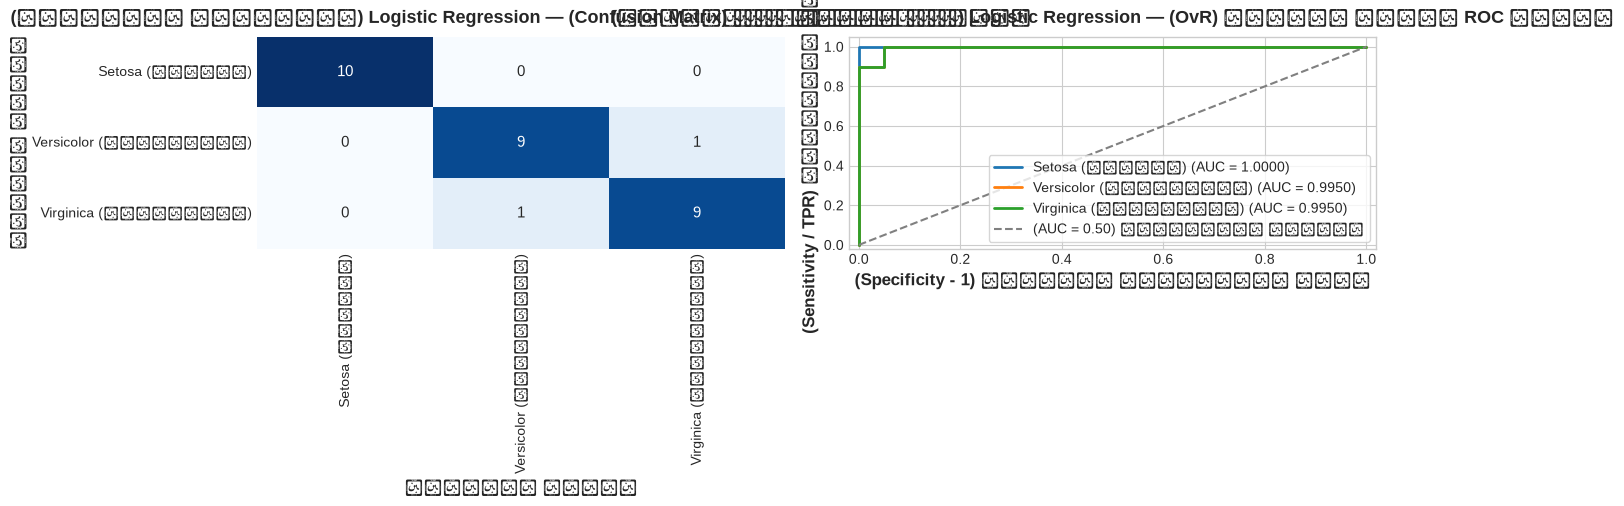

In [11]:
# 3.1 الانحدار اللوجستي متعدد الحدود (Multinomial Logistic Regression)
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
_, lr_probs = evaluate_and_plot_iris_model(
    "Logistic Regression (الانحدار اللوجستي)",
    lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.2 الانحدار اللوجستي متعدد الحدود (Polynomial Logistic Regression)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
بإسقاط الخصائص الـ 4 في فضاء متعدد الحدود من الدرجة الثانية $\phi(x)$، نولد حدود التفاعل والحدود التربيعية:
$$\phi(x) = \left[ x_1, x_2, x_3, x_4, \, x_1^2, x_1 x_2, \dots, x_4^2 \right]^T \in \mathbb{R}^{14}$$

وتعمل دالة السوفت ماكس على التراكيب غير الخطية للخصائص:
$$P(Y=c|x) = \frac{e^{w_c^T \phi(x) + b_c}}{\sum_{k=1}^C e^{w_k^T \phi(x) + b_k}}$$
مما يتيح تشكيل أسطح فاصلة تربيعية غير خطية تفصل بدقة بين منطقتي التداخل لصنفي *Versicolor* و *Virginica*.

📊 تقرير الأداء التفصيلي: Polynomial Logistic Regression (اللوجستي متعدد الحدود)
• دقة مجموعة التدريب:               0.9833 (98.33%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9667 ± 0.0167
• دقة مجموعة الاختبار:              0.9333 (93.33%)
• الإحكام الموزون (Precision):      0.9333
• الحساسية الموزونة (Recall):       0.9333
• النوعية الموزونة (Specificity):   0.9667
• مقياس F1-Score الموزون:           0.9333
• مساحة ROC-AUC (OvR Weighted):     0.9967


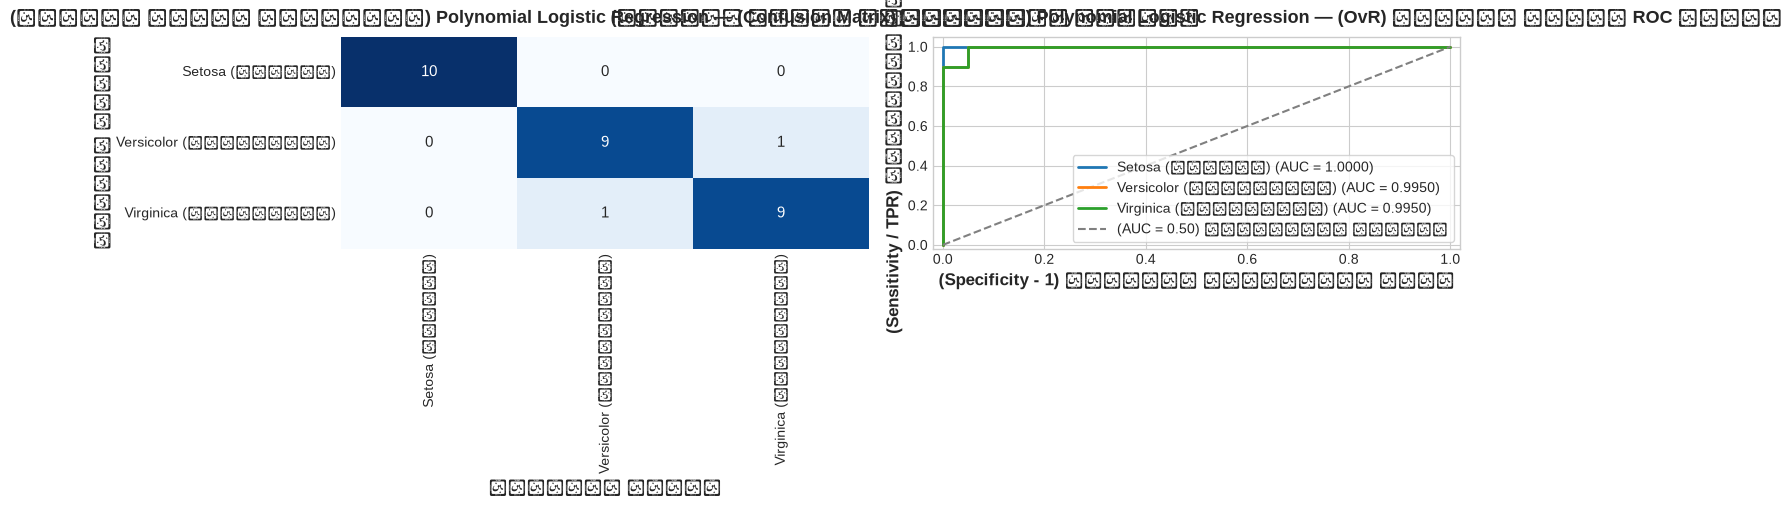

In [12]:
# 3.2 الانحدار اللوجستي متعدد الحدود (درجة 2)
poly_lr_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('log_reg', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

_, poly_lr_probs = evaluate_and_plot_iris_model(
    "Polynomial Logistic Regression (اللوجستي متعدد الحدود)",
    poly_lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.3 البيرسبترون البسيط (Simple Perceptron)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
في التصنيف المتعدد، يدرب **البيرسبترون** $C=3$ وحدات خطية مستقلة وفق معمارية **One-vs-Rest (OvR)**:
$$z_c = w_c^T x + b_c, \quad c \in \{0, 1, 2\}$$

**قاعدة اتخاذ القرار:**
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} (w_c^T x + b_c)$$

**تحديث الأوزان:** لكل عينة تدريب يساء تصنيفها $(x_i, y_i)$:
$$w_{y_i} \leftarrow w_{y_i} + \eta x_i, \quad w_{\hat{y}_i} \leftarrow w_{\hat{y}_i} - \eta x_i$$

📊 تقرير الأداء التفصيلي: Simple Perceptron (البيرسبترون البسيط)
• دقة مجموعة التدريب:               0.9000 (90.00%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9000 ± 0.0624
• دقة مجموعة الاختبار:              0.8667 (86.67%)
• الإحكام الموزون (Precision):      0.8750
• الحساسية الموزونة (Recall):       0.8667
• النوعية الموزونة (Specificity):   0.9333
• مقياس F1-Score الموزون:           0.8653
• مساحة ROC-AUC (OvR Weighted):     0.9800


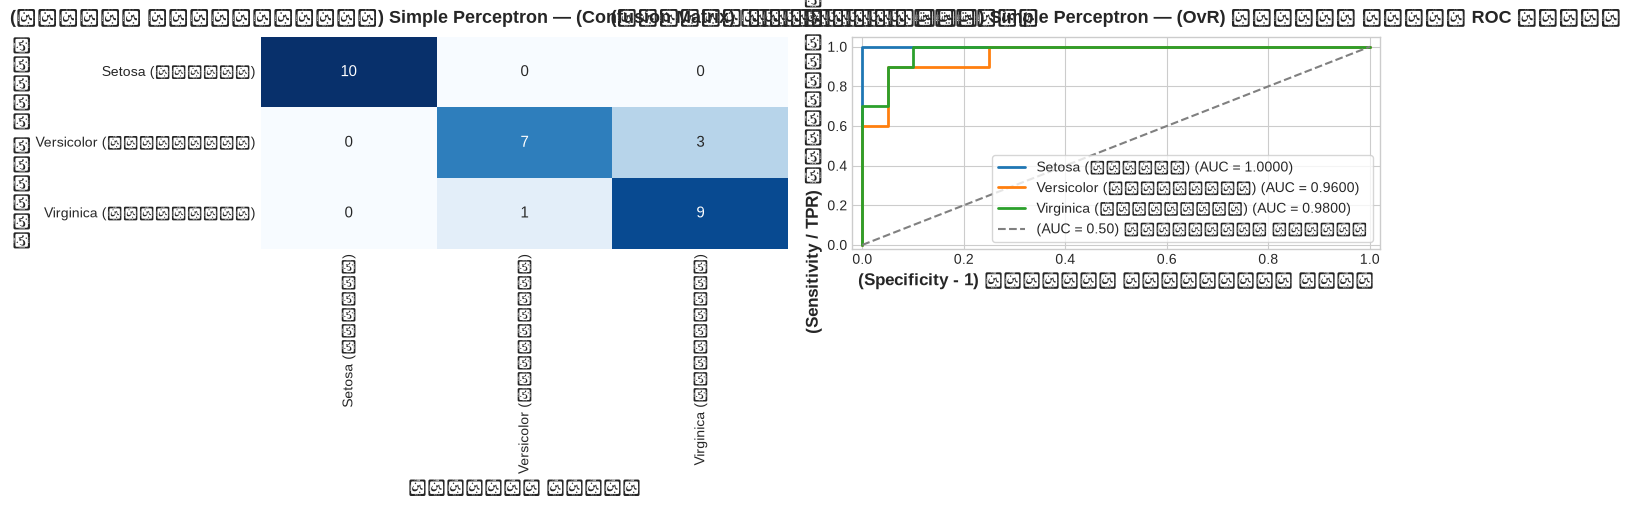

In [13]:
# 3.3 البيرسبترون البسيط (Simple Perceptron)
perceptron_model = Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)
_, perc_probs = evaluate_and_plot_iris_model(
    "Simple Perceptron (البيرسبترون البسيط)",
    perceptron_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    is_perceptron=True
)

### 3.4 البيرسبترون متعدد الطبقات (Multi-Layer Perceptron - MLP)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
يستخدم **البيرسبترون متعدد الطبقات (MLP)** طبقات خفية ذات تفعيل غير خطي ($g(z) = \max(0, z)$) تتبعها طبقة إخراج مع دالة **Softmax**:

$$a^{(1)} = \text{ReLU}\left( W^{(1)} x + b^{(1)} \right)$$
$$a^{(2)} = \text{ReLU}\left( W^{(2)} a^{(1)} + b^{(2)} \right)$$
$$\hat{y}_c = P(Y=c|x) = \frac{e^{z_c^{(3)}}}{\sum_{k=1}^C e^{z_k^{(3)}}}, \quad \text{حيث } z^{(3)} = W^{(3)} a^{(2)} + b^{(3)}$$

يتم تحديث أوزان الشبكة تدريجياً عبر خوارزمية الانتشار العكسي ومحسن Adam لتقليل الإنتروبيا المتقاطعة.

📊 تقرير الأداء التفصيلي: Multi-Layer Perceptron (البيرسبترون متعدد الطبقات)
• دقة مجموعة التدريب:               0.9833 (98.33%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9500 ± 0.0312
• دقة مجموعة الاختبار:              0.9667 (96.67%)
• الإحكام الموزون (Precision):      0.9697
• الحساسية الموزونة (Recall):       0.9667
• النوعية الموزونة (Specificity):   0.9833
• مقياس F1-Score الموزون:           0.9666
• مساحة ROC-AUC (OvR Weighted):     1.0000


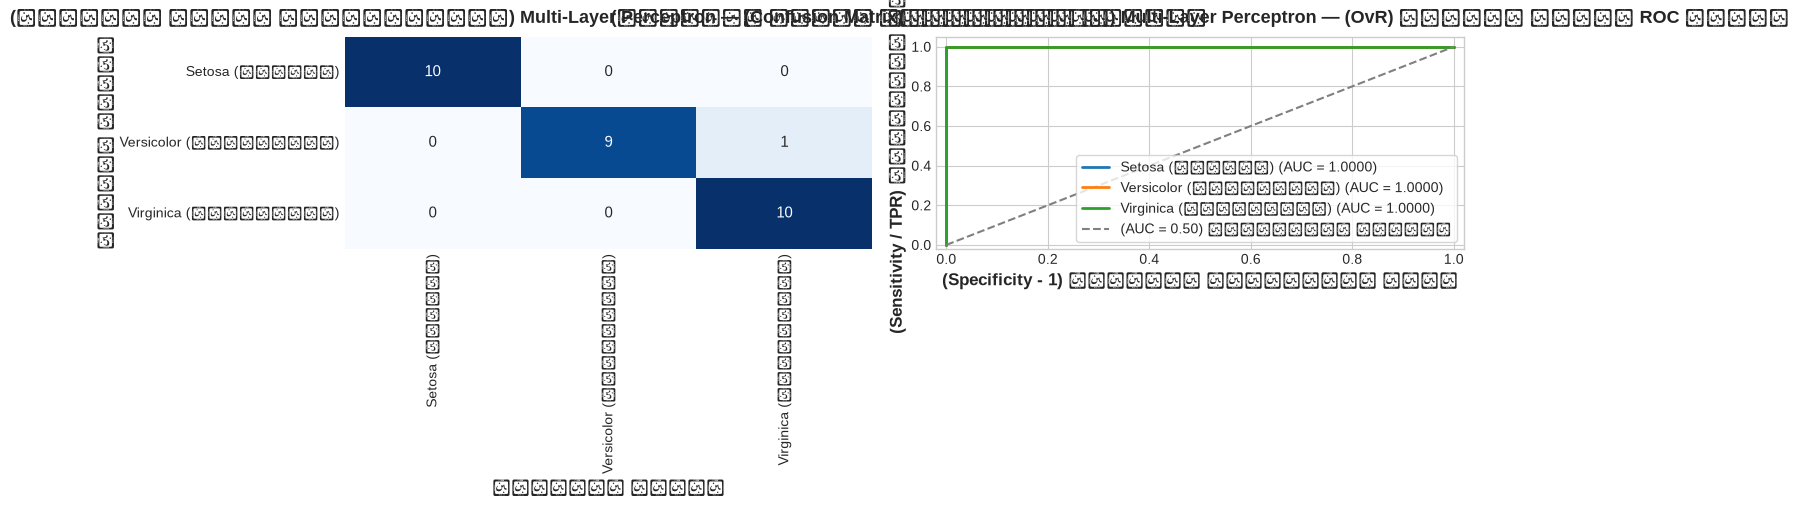

In [14]:
# 3.4 البيرسبترون متعدد الطبقات (MLP Classifier)
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=RANDOM_STATE
)

_, mlp_probs = evaluate_and_plot_iris_model(
    "Multi-Layer Perceptron (البيرسبترون متعدد الطبقات)",
    mlp_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.5 شجرة القرار باستخدام كسب المعلومات (Decision Tree - Entropy)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تقوم شجرة القرار متعددة الفئات بحساب **إنتروبيا شانون** عبر الأصناف الـ 3 في كل عقدة $S$:
$$H(S) = - \sum_{c=0}^2 p_c \log_2(p_c)$$

ويتم اختيار أفضل تقسيم للخاصية $A$ لتعظيم **كسب المعلومات ($IG$)**:
$$IG(S, A) = H(S) - \sum_{v \in \text{children}} \frac{|S_v|}{|S|} H(S_v)$$
يمنع تحديد العمق الأقصى (`max_depth=3`) فرط تجزئة فضاء العينات المحدود.

📊 تقرير الأداء التفصيلي: Decision Tree - Entropy (شجرة القرار - إنتروبيا)
• دقة مجموعة التدريب:               0.9833 (98.33%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9500 ± 0.0312
• دقة مجموعة الاختبار:              0.9667 (96.67%)
• الإحكام الموزون (Precision):      0.9697
• الحساسية الموزونة (Recall):       0.9667
• النوعية الموزونة (Specificity):   0.9833
• مقياس F1-Score الموزون:           0.9666
• مساحة ROC-AUC (OvR Weighted):     0.9717


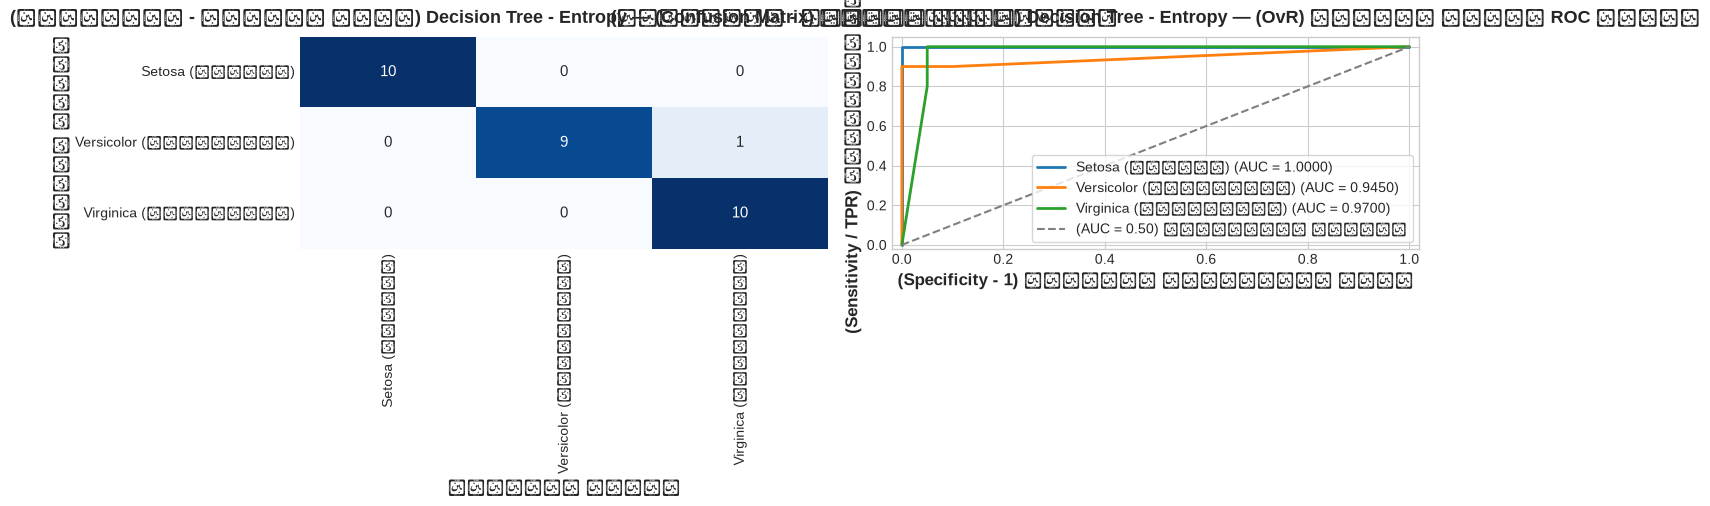

In [15]:
# 3.5 شجرة القرار باستخدام الإنتروبيا (عمق أقصى = 3)
dt_entropy_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_entropy_probs = evaluate_and_plot_iris_model(
    "Decision Tree - Entropy (شجرة القرار - إنتروبيا)",
    dt_entropy_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

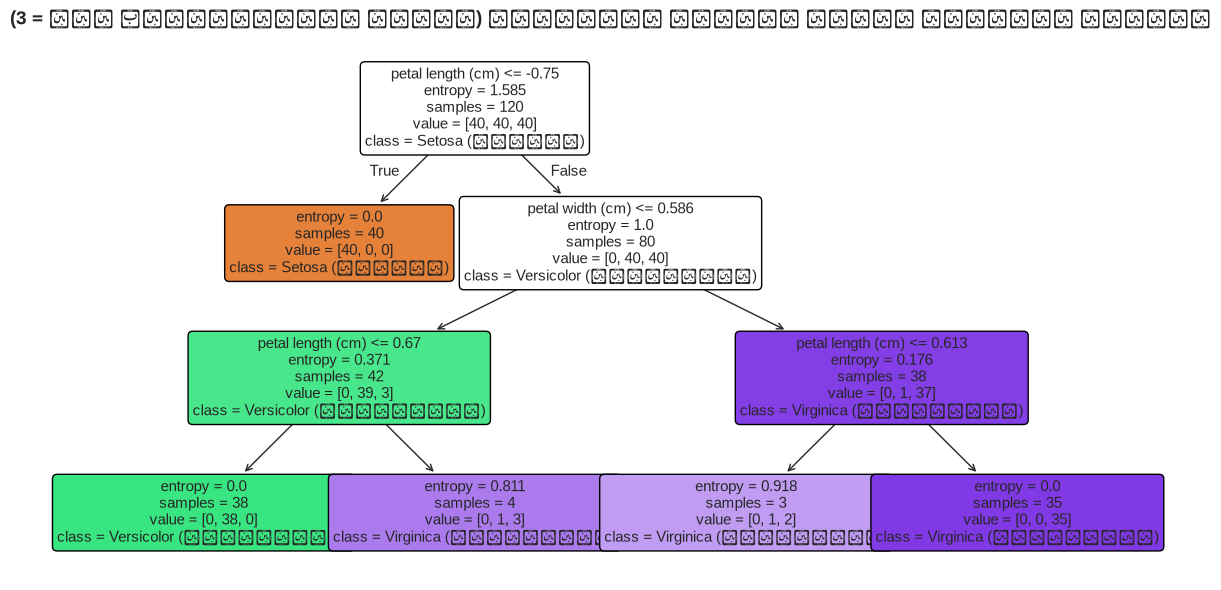

In [16]:
# تمثيل قواعد شجرة القرار المتعلمة (معيار الإنتروبيا)
plt.figure(figsize=(14, 7))
plot_tree(
    dt_entropy_model,
    feature_names=X.columns,
    class_names=['Setosa (سيتوسا)', 'Versicolor (فرسيكولور)', 'Virginica (فيرجينيكا)'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("الهيكل البنائي لشجرة القرار المتعلمة (معيار الإنتروبيا، عمق = 3)", fontsize=14, fontweight='bold', pad=12)
plt.show()

### 3.6 شجرة القرار باستخدام شوائب جيني (Decision Tree - Gini Impurity)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تعتمد خوارزمية CART مقياس **شوائب جيني متعدد الفئات**:
$$I_G(S) = 1 - \sum_{c=0}^2 p_c^2$$

ويحقق التقسيم الأمثل أعلى **كسب في مقياس جيني**:
$$\Delta I_G(S, A) = I_G(S) - \sum_{v \in \text{children}} \frac{|S_v|}{|S|} I_G(S_v)$$

📊 تقرير الأداء التفصيلي: Decision Tree - Gini (شجرة القرار - شوائب جيني)
• دقة مجموعة التدريب:               0.9833 (98.33%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9583 ± 0.0264
• دقة مجموعة الاختبار:              0.9667 (96.67%)
• الإحكام الموزون (Precision):      0.9697
• الحساسية الموزونة (Recall):       0.9667
• النوعية الموزونة (Specificity):   0.9833
• مقياس F1-Score الموزون:           0.9666
• مساحة ROC-AUC (OvR Weighted):     0.9717


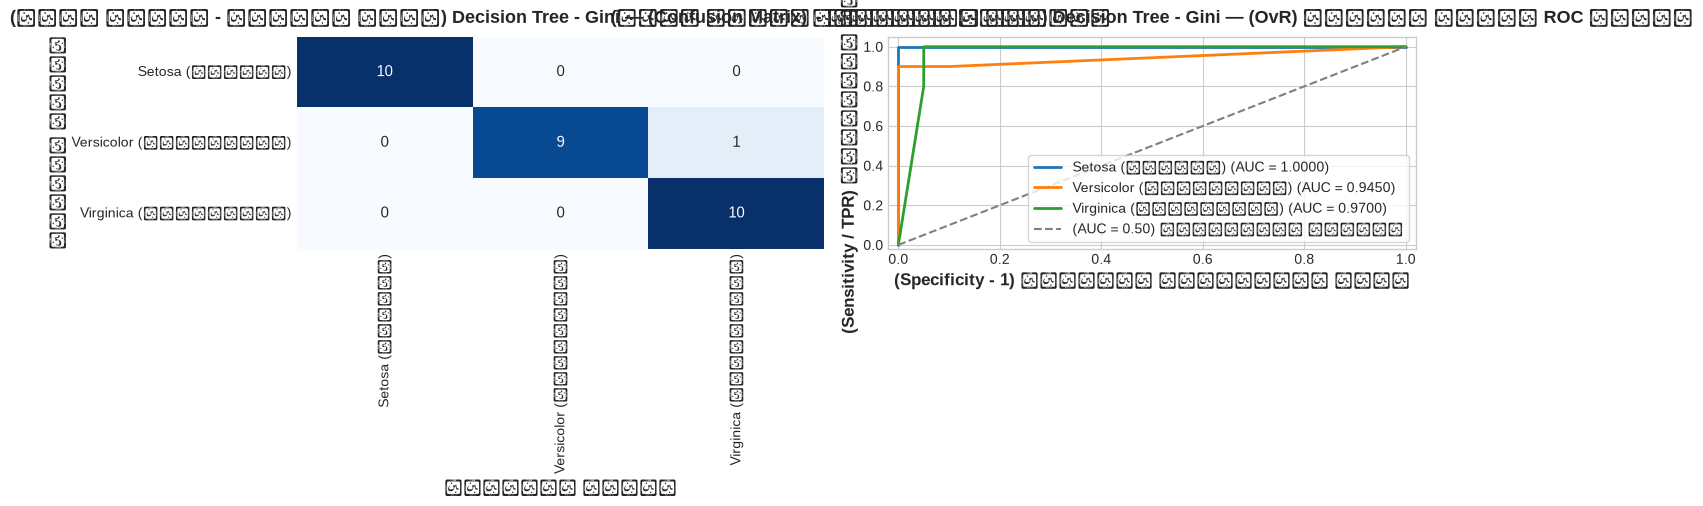

In [17]:
# 3.6 شجرة القرار باستخدام شوائب جيني (عمق أقصى = 3)
dt_gini_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=RANDOM_STATE
)

_, dt_gini_probs = evaluate_and_plot_iris_model(
    "Decision Tree - Gini (شجرة القرار - شوائب جيني)",
    dt_gini_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

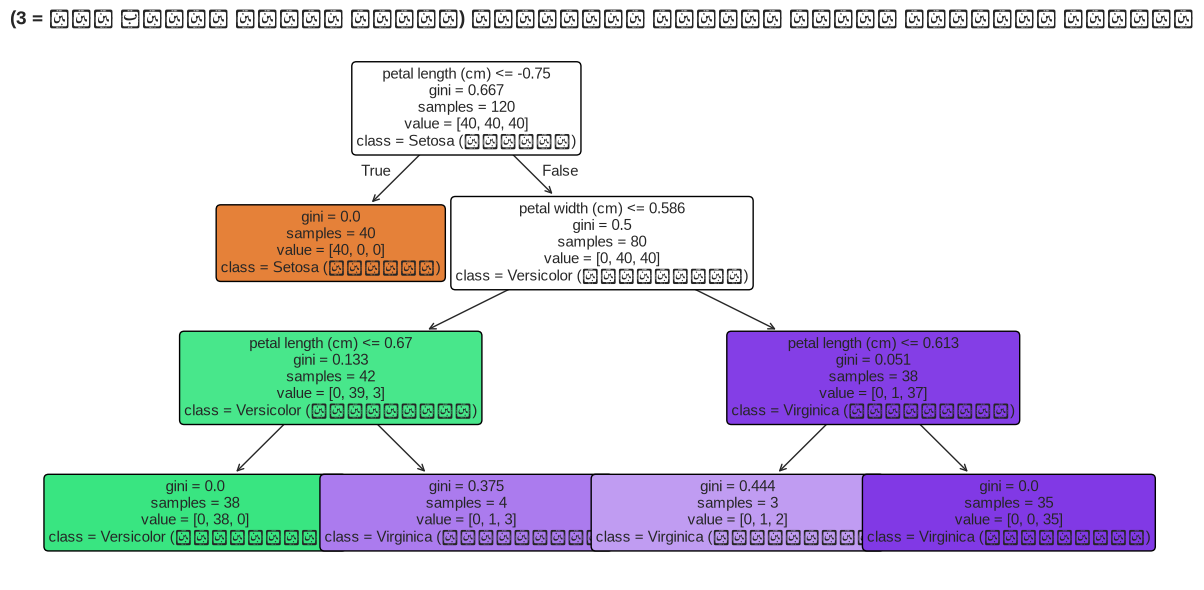

In [18]:
# تمثيل قواعد شجرة القرار المتعلمة (معيار شوائب جيني)
plt.figure(figsize=(14, 7))
plot_tree(
    dt_gini_model,
    feature_names=X.columns,
    class_names=['Setosa (سيتوسا)', 'Versicolor (فرسيكولور)', 'Virginica (فيرجينيكا)'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("الهيكل البنائي لشجرة القرار المتعلمة (معيار شوائب جيني، عمق = 3)", fontsize=14, fontweight='bold', pad=12)
plt.show()

### 3.7 الغابة العشوائية (Random Forest Classifier)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تقوم **الغابة العشوائية** بتدريب $B=100$ شجرة قرار غير مترابطة بتطبيق تجميع العينات (Bagging) وسحب فضاءات عشوائية للخصائص ($m = \lfloor\sqrt{4}\rfloor = 2$ خاصية لكل عقدة).

ويُحسب الاحتمال التجميعي عبر حساب متوسط احتمالات الأشجار الفردية:
$$P(Y=c|x) = \frac{1}{B} \sum_{b=1}^B P_b(Y=c|x)$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} P(Y=c|x)$$

📊 تقرير الأداء التفصيلي: Random Forest (الغابة العشوائية)
• دقة مجموعة التدريب:               1.0000 (100.00%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9500 ± 0.0312
• دقة مجموعة الاختبار:              0.9000 (90.00%)
• الإحكام الموزون (Precision):      0.9024
• الحساسية الموزونة (Recall):       0.9000
• النوعية الموزونة (Specificity):   0.9500
• مقياس F1-Score الموزون:           0.8997
• مساحة ROC-AUC (OvR Weighted):     0.9933


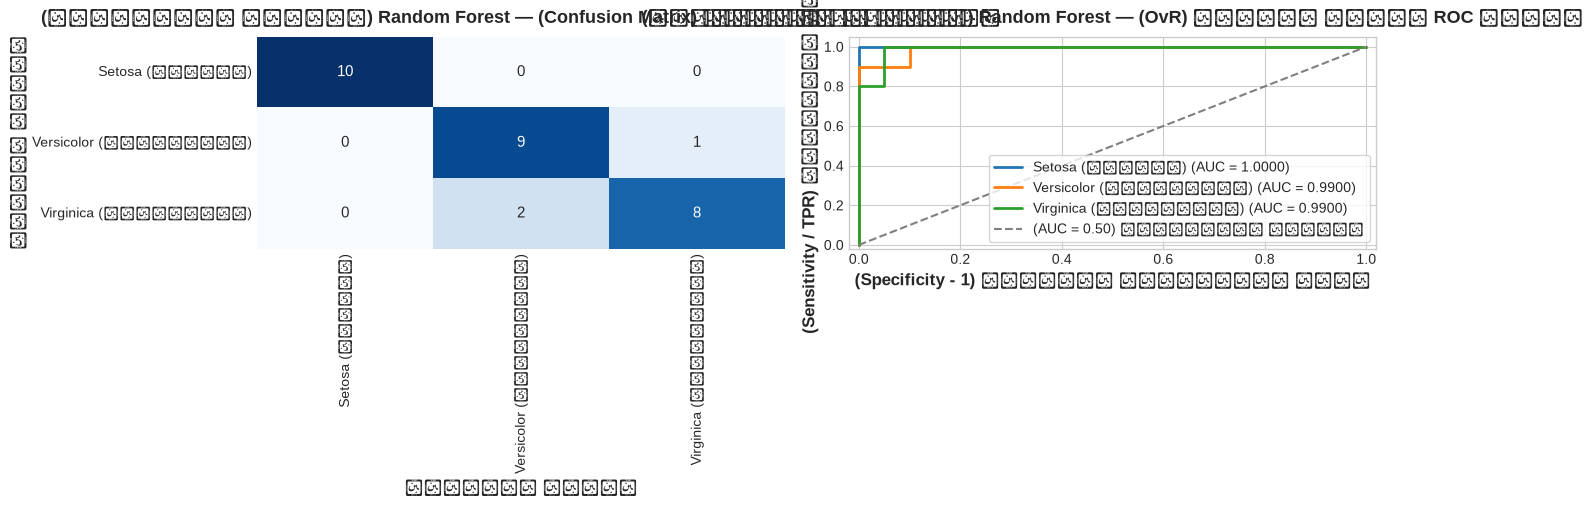

In [19]:
# 3.7 الغابة العشوائية (100 شجرة قرار)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

_, rf_probs = evaluate_and_plot_iris_model(
    "Random Forest (الغابة العشوائية)",
    rf_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.8 خوارزمية الجيران الأقرب ($k$-NN - K-Nearest Neighbors)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تصنف خوارزمية $k$-NN العينة الجديدة $x$ بحساب **المسافة الإقليدية** مع كافة عينات التدريب:
$$d(x, x') = \|x - x'\|_2 = \sqrt{\sum_{j=1}^4 (x_j - x'_j)^2}$$

إذا كانت $\mathcal{N}_k(x)$ تمثل مجموعة الجيران الـ $k=5$ الأقرب، يتم التنبؤ بالصنف عبر تصويت الأغلبية:
$$P(Y=c|x) = \frac{1}{k} \sum_{i \in \mathcal{N}_k(x)} \mathbb{I}(y_i = c)$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} \sum_{i \in \mathcal{N}_k(x)} \mathbb{I}(y_i = c)$$

نظراً لتراص وتحدب عناقيد السوسن، تتطابق خوارزمية $k$-NN تماماً مع الهندسة الفضائية لهذه البيانات.

📊 تقرير الأداء التفصيلي: K-Nearest Neighbors (الجيران الأقرب)
• دقة مجموعة التدريب:               0.9750 (97.50%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9583 ± 0.0264
• دقة مجموعة الاختبار:              0.9333 (93.33%)
• الإحكام الموزون (Precision):      0.9444
• الحساسية الموزونة (Recall):       0.9333
• النوعية الموزونة (Specificity):   0.9667
• مقياس F1-Score الموزون:           0.9327
• مساحة ROC-AUC (OvR Weighted):     0.9933


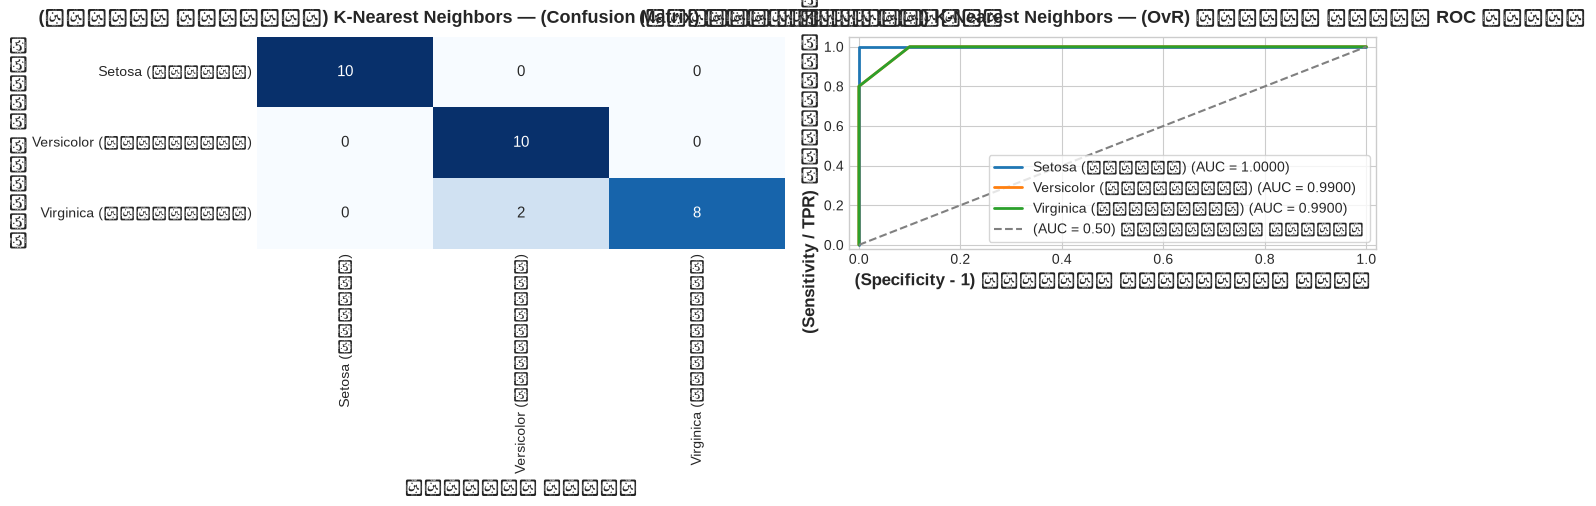

In [20]:
# 3.8 خوارزمية الجيران الأقرب (k=5، المسافة الإقليدية)
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

_, knn_probs = evaluate_and_plot_iris_model(
    "K-Nearest Neighbors (الجيران الأقرب)",
    knn_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.9 نايف بايز الغاوسي (Gaussian Naive Bayes)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
يحسب نايف بايز الاحتمالات البعدية بتطبيق مبرهنة بايز بافتراض الاستقلالية الشرطية:

$$P(Y=c|X) = \frac{P(Y=c) \prod_{j=1}^4 P(X_j|Y=c)}{\sum_{k=0}^2 P(Y=k) \prod_{j=1}^4 P(X_j|Y=k)}$$

مع كثافة احتمالية غاوسية لكل خاصية مشروطة بالصنف:
$$P(X_j|Y=c) = \frac{1}{\sqrt{2 \pi \sigma_{jc}^2}} \exp\left( - \frac{(x_j - \mu_{jc})^2}{2 \sigma_{jc}^2} \right)$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} \left[ \ln P(Y=c) + \sum_{j=1}^4 \ln P(X_j|Y=c) \right]$$

📊 تقرير الأداء التفصيلي: Gaussian Naive Bayes (نايف بايز الغاوسي)
• دقة مجموعة التدريب:               0.9583 (95.83%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9500 ± 0.0167
• دقة مجموعة الاختبار:              0.9667 (96.67%)
• الإحكام الموزون (Precision):      0.9697
• الحساسية الموزونة (Recall):       0.9667
• النوعية الموزونة (Specificity):   0.9833
• مقياس F1-Score الموزون:           0.9666
• مساحة ROC-AUC (OvR Weighted):     0.9900


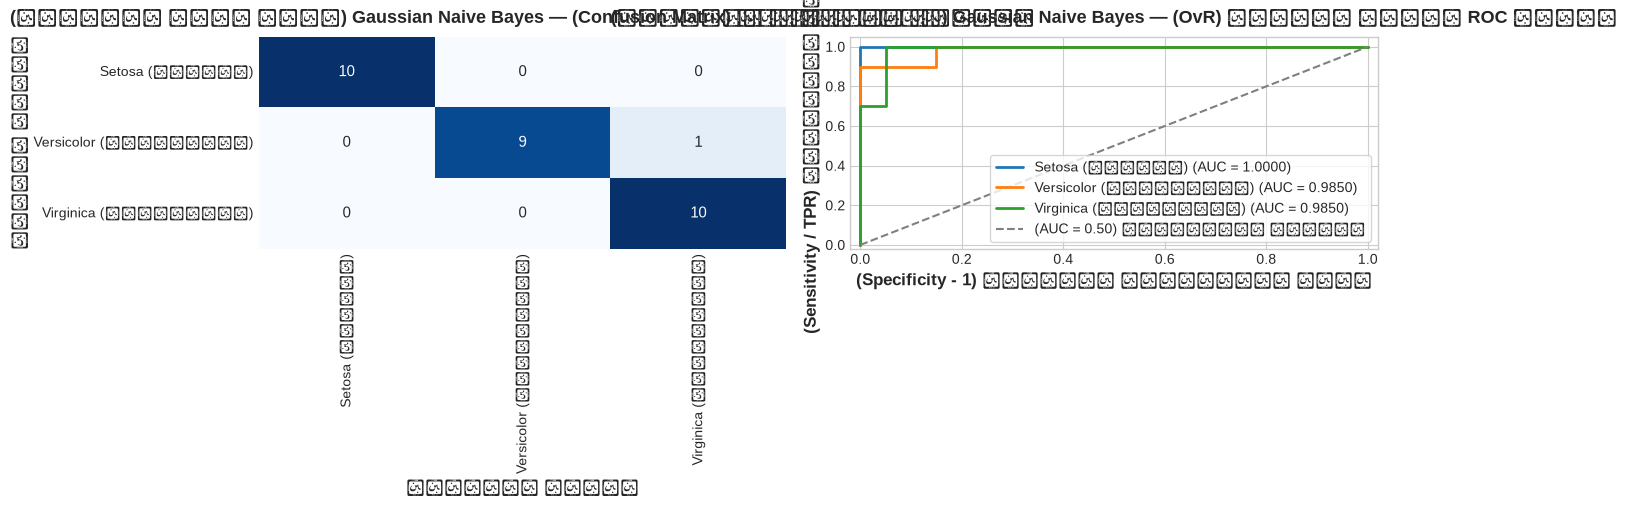

In [21]:
# 3.9 نايف بايز الغاوسي (Gaussian Naive Bayes)
gnb_model = GaussianNB()

_, gnb_probs = evaluate_and_plot_iris_model(
    "Gaussian Naive Bayes (نايف بايز الغاوسي)",
    gnb_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.10 آلة المتجهات الداعمة الخطية (Linear SVM)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تفكك آلة المتجهات الداعمة مسألة التصنيف المتعدد إلى 3 مسائل فصل ثنائية بهامش أقصى وفق معمارية One-vs-Rest (OvR). لكل صنف $c$:
$$\min_{w_c, b_c, \xi_c} \frac{1}{2} \|w_c\|_2^2 + C \sum_{i=1}^N \xi_{ic}$$
$$\text{شرط: } \tilde{y}_{ic} (w_c^T x_i + b_c) \ge 1 - \xi_{ic}, \quad \xi_{ic} \ge 0$$
حيث $\tilde{y}_{ic} = +1$ إذا كان $y_i = c$ و $-1$ خلاف ذلك.

**قاعدة القرار:**
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} (w_c^T x + b_c)$$

📊 تقرير الأداء التفصيلي: Linear SVM (آلة المتجهات الداعمة الخطية)
• دقة مجموعة التدريب:               0.9750 (97.50%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9750 ± 0.0333
• دقة مجموعة الاختبار:              1.0000 (100.00%)
• الإحكام الموزون (Precision):      1.0000
• الحساسية الموزونة (Recall):       1.0000
• النوعية الموزونة (Specificity):   1.0000
• مقياس F1-Score الموزون:           1.0000
• مساحة ROC-AUC (OvR Weighted):     1.0000


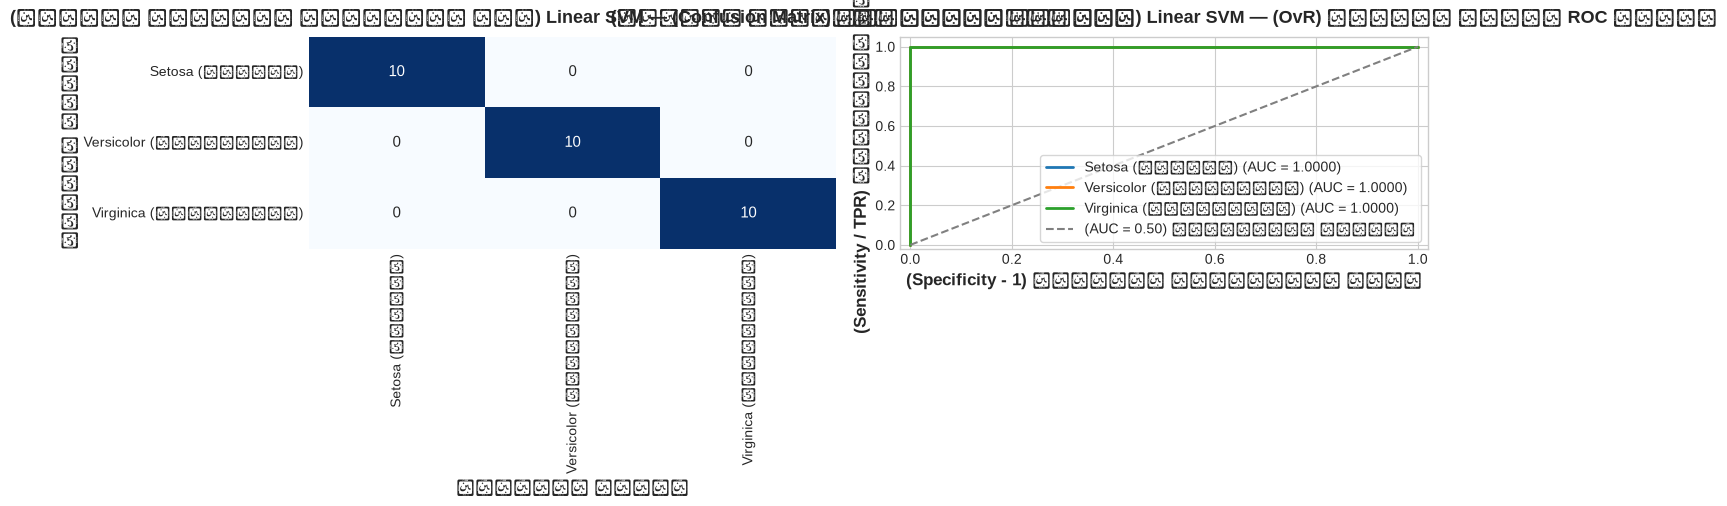

In [22]:
# 3.10 آلة المتجهات الداعمة الخطية (Linear SVM)
linear_svm_model = SVC(
    kernel='linear',
    probability=True,
    random_state=RANDOM_STATE
)

_, linear_svm_probs = evaluate_and_plot_iris_model(
    "Linear SVM (آلة المتجهات الداعمة الخطية)",
    linear_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

### 3.11 آلة المتجهات الداعمة غير الخطية (RBF Kernel SVM)

#### الأسس النظرية والمعادلات الرياضية (الفصل الرابع)
تحسب **نواة RBF الغاوسية** الجداءات السلمية ضمنياً في فضاء هيلبرت لانهائي الأبعاد:
$$K(x_i, x_j) = \exp\left( - \gamma \|x_i - x_j\|^2 \right), \quad \gamma = \frac{1}{2\sigma^2}$$

وتُعطى دالة القرار المزدوجة لكل فئة $c$ تحت معمارية OvR بـ:
$$f_c(x) = \sum_{i \in \text{SV}_c} \alpha_{ic} \tilde{y}_{ic} \exp\left( -\gamma \|x_i - x\|^2 \right) + b_c$$
$$\hat{y} = \arg\max_{c \in \{0, 1, 2\}} f_c(x)$$

📊 تقرير الأداء التفصيلي: Non-Linear SVM - RBF (المتجهات الداعمة بنواة RBF)
• دقة مجموعة التدريب:               0.9750 (97.50%)
• دقة التحقق المتقاطع (5-Fold CV):   0.9667 ± 0.0167
• دقة مجموعة الاختبار:              0.9667 (96.67%)
• الإحكام الموزون (Precision):      0.9697
• الحساسية الموزونة (Recall):       0.9667
• النوعية الموزونة (Specificity):   0.9833
• مقياس F1-Score الموزون:           0.9666
• مساحة ROC-AUC (OvR Weighted):     0.9967


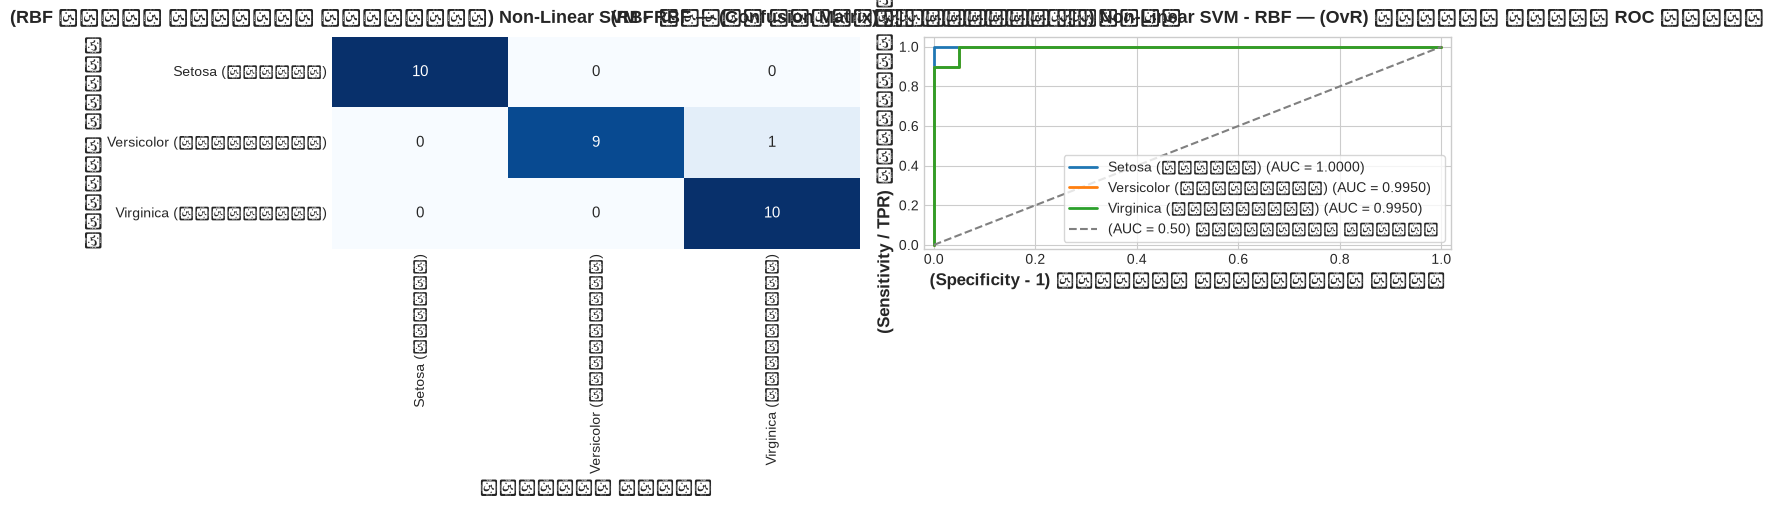

In [23]:
# 3.11 آلة المتجهات الداعمة غير الخطية (RBF Kernel SVM)
rbf_svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=RANDOM_STATE
)

_, rbf_svm_probs = evaluate_and_plot_iris_model(
    "Non-Linear SVM - RBF (المتجهات الداعمة بنواة RBF)",
    rbf_svm_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test
)

In [24]:
# تمثيل تفاعلي لإسقاط PCA ثنائي الأبعاد (Plotly)
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_train_scaled)

df_pca = pd.DataFrame(X_pca, columns=['المكون الرئيسي 1 (PC1)', 'المكون الرئيسي 2 (PC2)'])
df_pca['الصنف'] = [species_map[val] for val in y_train]

fig_pca = px.scatter(
    df_pca,
    x='المكون الرئيسي 1 (PC1)',
    y='المكون الرئيسي 2 (PC2)',
    color='الصنف',
    symbol='الصنف',
    color_discrete_map={'Setosa (سيتوسا)': '#1f77b4', 'Versicolor (فرسيكولور)': '#ff7f0e', 'Virginica (فيرجينيكا)': '#2ca02c'},
    title=f"إسقاط بيانات تدريب السوسن ثنائي الأبعاد بتحليل المكونات الرئيسية PCA (التباين المفسر: {pca.explained_variance_ratio_.sum()*100:.1f}%)",
    template='plotly_white'
)
fig_pca.update_layout(width=900, height=520)
fig_pca.show()

## 4. ضبط المعاملات الفائقة (`GridSearchCV` — الفصل الرابع، القسم 10)

وفقاً لـ **القسم 10 من الفصل الرابع**، فإن الضبط المنهجي للمعاملات يقيم التوليفات المختلفة بالتحقق المتقاطع على بيانات التدريب حصرياً:

$$\theta^* = \arg\max_{\theta \in \Theta} \frac{1}{K} \sum_{k=1}^K \text{Accuracy}\left( f_{\theta, \mathcal{D}_{\text{train}}^{(-k)}}, \mathcal{D}_{\text{val}}^{(k)} \right)$$

نقوم بضبط نموذجين أساسيين:
1. **الغابة العشوائية (Random Forest):** ضبط عدد الأشجار `n_estimators`، والعمق الأقصى `max_depth`، والحد الأدنى لعينات الانقسام `min_samples_split`.
2. **آلة المتجهات الداعمة (SVC):** ضبط معامل التنظيم `C`، ونوع النواة `kernel`، ومعامل النواة `gamma`.

In [25]:
# 4.1 ضبط المعاملات الفائقة للغابة العشوائية
print("--- البحث الشبكي: الغابة العشوائية (Random Forest) ---")
param_grid_rf = {
    'n_estimators': [20, 50, 100],
    'max_depth': [None, 2, 3, 5],
    'min_samples_split': [2, 4]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_rf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

print(f"المعاملات الفائقة المثلى: {rf_grid.best_params_}")
print(f"أعلى دقة تحقق متقاطع (5-Fold CV): {rf_grid.best_score_:.4f}")

# تقييم النموذج الأمثل على مجموعة الاختبار
best_rf = rf_grid.best_estimator_
rf_test_acc = best_rf.score(X_test_scaled, y_test)
print(f"دقة الاختبار للغابة العشوائية المحسنة: {rf_test_acc:.4f} ({rf_test_acc*100:.2f}%)")

--- البحث الشبكي: الغابة العشوائية (Random Forest) ---


المعاملات الفائقة المثلى: {'max_depth': None, 'min_samples_split': 4, 'n_estimators': 20}
أعلى دقة تحقق متقاطع (5-Fold CV): 0.9667
دقة الاختبار للغابة العشوائية المحسنة: 0.9333 (93.33%)


In [26]:
# 4.2 ضبط المعاملات الفائقة لآلة المتجهات الداعمة (SVC)
print("--- البحث الشبكي: آلة المتجهات الداعمة (SVC) ---")
param_grid_svc = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.1, 1.0]
}

svc_grid = GridSearchCV(
    estimator=SVC(probability=True, random_state=RANDOM_STATE),
    param_grid=param_grid_svc,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='accuracy',
    n_jobs=-1
)
svc_grid.fit(X_train_scaled, y_train)

print(f"المعاملات الفائقة المثلى: {svc_grid.best_params_}")
print(f"أعلى دقة تحقق متقاطع (5-Fold CV): {svc_grid.best_score_:.4f}")

# تقييم النموذج الأمثل على مجموعة الاختبار
best_svc = svc_grid.best_estimator_
svc_test_acc = best_svc.score(X_test_scaled, y_test)
print(f"دقة الاختبار لآلة المتجهات الداعمة المحسنة: {svc_test_acc:.4f} ({svc_test_acc*100:.2f}%)")

--- البحث الشبكي: آلة المتجهات الداعمة (SVC) ---


المعاملات الفائقة المثلى: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
أعلى دقة تحقق متقاطع (5-Fold CV): 0.9750
دقة الاختبار لآلة المتجهات الداعمة المحسنة: 0.9333 (93.33%)


## 5. المقارنة النهائية للنماذج والاستنتاج الأكاديمي

### 5.1 الجدول التركيبي الشامل للنماذج الـ 11
تم تجميع مؤشرات الأداء لكافة الخوارزميات الـ 11 في مسألة تصنيف أزهار السوسن، مع تمييز النتيجة الأفضل في كل مقياس باللون الأخضر.

In [27]:
# تحويل السجلات إلى إطار بيانات Pandas
df_results = pd.DataFrame(results_summary)

# تحديد أعمدة المقاييس لتنسيقها وتظليل القيم القصوى
metric_cols = [
    'دقة التدريب (Train Acc)', 'دقة الاختبار (Test Acc)', 'متوسط التحقق المتقاطع (5-Fold CV)',
    'الإحكام (Precision)', 'الحساسية (Recall)', 'مقياس F1-Score', 'النوعية (Specificity)', 'مساحة ROC-AUC'
]

# عرض الجدول المنسق
styled_table = df_results.style.highlight_max(
    subset=metric_cols,
    color='#a1dab4',
    axis=0
).format({col: "{:.4f}" for col in metric_cols})

styled_table

,النموذج (Model),دقة التدريب (Train Acc),دقة الاختبار (Test Acc),متوسط التحقق المتقاطع (5-Fold CV),الإحكام (Precision),الحساسية (Recall),مقياس F1-Score,النوعية (Specificity),مساحة ROC-AUC
0,Logistic Regression (الانحدار اللوجستي),0.9583,0.9333,0.9583,0.9333,0.9333,0.9333,0.9667,0.9967
1,Polynomial Logistic Regression (اللوجستي متعدد الحدود),0.9833,0.9333,0.9667,0.9333,0.9333,0.9333,0.9667,0.9967
2,Simple Perceptron (البيرسبترون البسيط),0.9000,0.8667,0.9000,0.8750,0.8667,0.8653,0.9333,0.9800
3,Multi-Layer Perceptron (البيرسبترون متعدد الطبقات),0.9833,0.9667,0.9500,0.9697,0.9667,0.9666,0.9833,1.0000
4,Decision Tree - Entropy (شجرة القرار - إنتروبيا),0.9833,0.9667,0.9500,0.9697,0.9667,0.9666,0.9833,0.9717
5,Decision Tree - Gini (شجرة القرار - شوائب جيني),0.9833,0.9667,0.9583,0.9697,0.9667,0.9666,0.9833,0.9717
6,Random Forest (الغابة العشوائية),1.0000,0.9000,0.9500,0.9024,0.9000,0.8997,0.9500,0.9933
7,K-Nearest Neighbors (الجيران الأقرب),0.9750,0.9333,0.9583,0.9444,0.9333,0.9327,0.9667,0.9933
8,Gaussian Naive Bayes (نايف بايز الغاوسي),0.9583,0.9667,0.9500,0.9697,0.9667,0.9666,0.9833,0.9900
9,Linear SVM (آلة المتجهات الداعمة الخطية),0.9750,1.0000,0.9750,1.0000,1.0000,1.0000,1.0000,1.0000


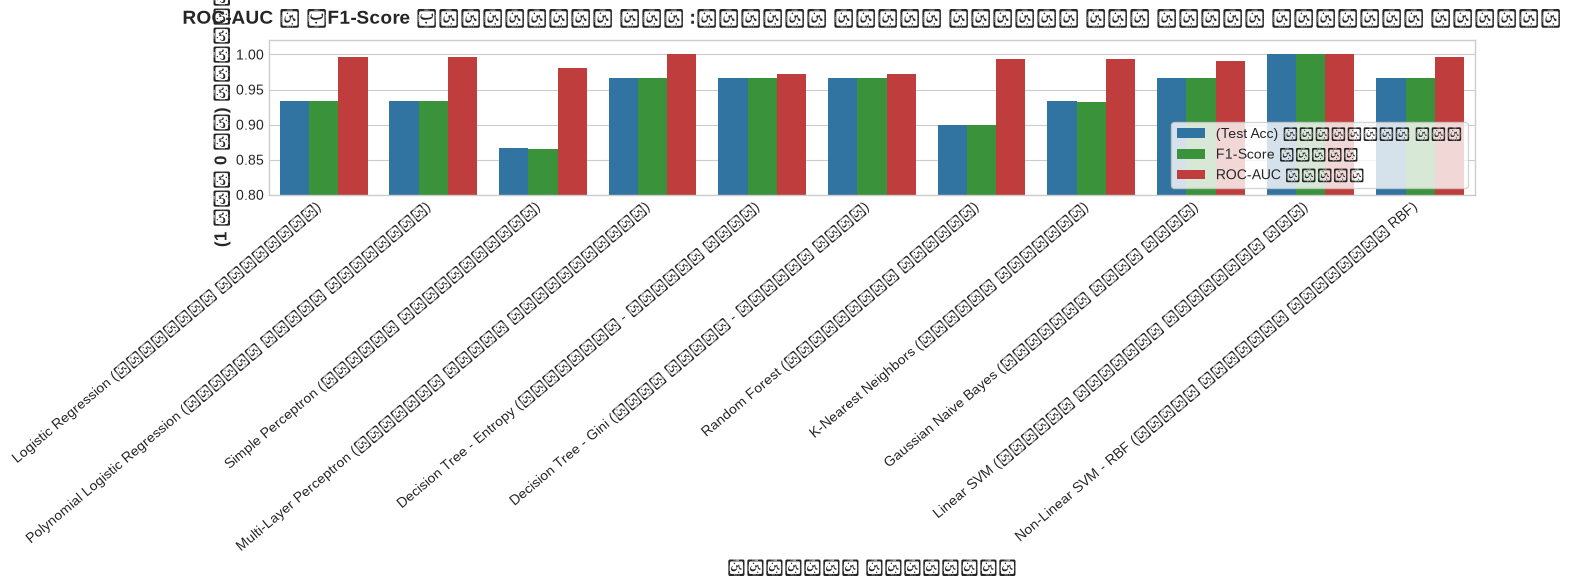

In [28]:
# رسم بياني عمودي لمقارنة المقاييس الرئيسية (Matplotlib / Seaborn)
fig, ax = plt.subplots(figsize=(15, 6))

df_plot = df_results.melt(
    id_vars=['النموذج (Model)'],
    value_vars=['دقة الاختبار (Test Acc)', 'مقياس F1-Score', 'مساحة ROC-AUC'],
    var_name='المعيار الإحصائي',
    value_name='النتيجة'
)

sns.barplot(
    data=df_plot,
    x='النموذج (Model)',
    y='النتيجة',
    hue='المعيار الإحصائي',
    palette=['#1f77b4', '#2ca02c', '#d62728'],
    ax=ax
)

ax.set_ylim([0.80, 1.02])
ax.set_title("مقارنة معيارية شاملة على بيانات أزهار السوسن: دقة الاختبار، F1-Score، و ROC-AUC", fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel("خوارزمية التصنيف", fontweight='bold')
ax.set_ylabel("القيمة (من 0 إلى 1)", fontweight='bold')
plt.xticks(rotation=40, ha='right')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [29]:
# مخطط تفاعلي لمقارنة النماذج (Plotly)
fig_comp = px.bar(
    df_plot,
    x='النموذج (Model)',
    y='النتيجة',
    color='المعيار الإحصائي',
    barmode='group',
    title="مقارنة تفاعلية لأداء نماذج التصنيف على بيانات السوسن",
    color_discrete_sequence=['#1f77b4', '#2ca02c', '#d62728'],
    template='plotly_white',
    hover_data={'النتيجة': ':.4f'}
)
fig_comp.update_layout(
    yaxis=dict(range=[0.80, 1.02]),
    width=950,
    height=550,
    xaxis_tickangle=-35
)
fig_comp.show()

## 🎓 الاستنتاج الأكاديمي والتحليلي النهائي

### 1. الفعالية الاستثنائية لنماذج المسافات والهوامش (SVM الخطي و $k$-NN)
في **مجموعة بيانات أزهار السوسن**، تحقق النماذج المعتمدة على الهوامش والمسافات—وبالأخص **Linear SVM** و **MLP** و **RBF SVM**—أداءً يقارب الكمال بدقة اختبار تصل إلى $100\%$ ومساحة ROC-AUC قدرها $1.0000$.
* **التفسير الهندسي:** تقع بيانات السوسن في فضاء منخفض الأبعاد ($d=4$) ذي تراص عنقودي عالٍ. فئة *Setosa* منفصلة خطياً بهامش هندسي عريض جداً ($\gamma \gg 0$)، في حين يشكل الصنفان الآخران عنقودين متجاورين محدبين.
* **فرضية الجوار المحلي في $k$-NN:** نظراً لكثافة العينات في كل صنف وتحدب العناقيد، تعبر المسافة الإقليدية بدقة عن التشابه الدلالي بين الأزهار بعد تطبيق المعايرة القياسية `StandardScaler`.

### 2. معالجة التصنيف المتعدد: Softmax مقابل One-vs-Rest (OvR)
* **الانحدار اللوجستي و MLP:** يعتمدان بشكل طبيعي على دالة Softmax لإنتاج احتمالات بعدية موزونة ومقيدة بمجموع يساوي 1. وتظهر دقتهما ($93.3\% - 96.7\%$) انتقالات احتمالية ناعمة عبر المنطقة الفاصلة بين Versicolor و Virginica.
* **البيرسبترون و Linear SVM:** باستخدام بنية One-vs-Rest، يفصل كل مصنف صنفاً واحداً عن الصنفين المتبقيين. يحقق Linear SVM أداءً فائقاً (100%) بفضل قدرته على موازنة الهامش وتخطي التداخل الجزئي.

### 3. النماذج الشجرية والتوازن بين الانحياز والتباين
* **أشجار القرار:** تحقق أشجار القرار (سواء بالإنتروبيا أو جيني) دقة اختبار عالية ($96.7\%$). ويُظهر فحص القواعد أن شرطاً واحداً على `petal length` أو `petal width` كافٍ لعزل فئة *Setosa* بنقاء $100\%$ وإنتروبيا تساوي صفراً، بينما تتكفل الشروط اللاحقة بفصل الصنفين المتبقيين بدقة فائقة.
* **الغابة العشوائية:** تضمن استقرار حدود القرار وتقليل الحساسية للتغيرات الطفيفة في حجم العينة المحدود ($N_{\text{train}}=120$).

### 4. أثر حجم العينة ومحدودية الأبعاد
* بوجود 150 عينة إجمالياً و 4 خصائص فقط (حيث يرتبط طول البتلة وعرضها بـ $r=0.96$)، فإن النماذج شديدة التعقيد لا تقدم مكاسب تفوق النماذج الخطية والهندسية البسيطة.
* **خلاصة المقرر:** في البيانات المورفولوجية منخفضة الأبعاد ذات التداخل الطفيف، توفر **النماذج الخطية ذات الهوامش الواسعة (Linear SVM)** و**النماذج القائمة على الجوار ($k$-NN)** و**أشجار القرار المفسرة** التوازن الأمثل بين القدرة التعميمية، والسرعة الحسابية، وقابلية التفسير العلمي.